# Experiment 3: When is exploration worth its cost?

Experiment 1 showed that methods can spend its budget either discovering basin or refining a solution. Experiment 2A showed that replacing ten EI proposals with uniform probes helped BO-EI recover after an early miss. We now test whether the same probes also carry a refinement cost when the initial design already contains a useful point in B. For CMA-ES, we test whether a wider initial population helps discover B from A and whether a smaller population spread helps refine B.

For each seed, we use two initial designs. Both contain the same eight background points, drawn uniformly outside the radius-1 neighbourhoods of A and B. The other four points use the same rotated pattern around either A or B, at distances $0.35$, $0.39$, $0.43$, and $0.47$ from the chosen minimiser.

| Initial design | Best observed value | What we measure |
|---|---:|---|
| Near A | $1.1225$ | Discovery of B, refinement of A, and final precision in B |
| Near B | $0.1225$ | Speed and success of refinement in B |

Within each starting situation, all four variants begin with the same 12 evaluated points and have 38 calls left. BO-EI fits its GP to those observations.

| Method | Variants | Hypothesis |
|---|---|---|
| BO-EI | Ordinary EI and EI with ten uniform probes | Probes help discover B from near A. From near B, replacing EI proposals with probes may slow refinement. |
| CMA-ES | Default scale $\sigma_0=0.25$ and small scale $\sigma_0=0.05$ | The default scale helps discover B from near A. The smaller scale concentrates proposals and may improve refinement from near B. |

## 1. Setup

The next cell loads the methods and configurations from the companion notebooks. We reuse the BO settings and uniform-probe schedule from Experiment 2A.

In [1]:
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from skopt import Optimizer
from skopt.space import Real
from skopt.utils import cook_estimator, normalize_dimensions
from threadpoolctl import threadpool_limits

# Supports starting Jupyter from either the repository root or code/.
code_dir = Path("code") if Path("code/configurations.ipynb").is_file() else Path(".")

for filename in ("methods.ipynb", "configurations.ipynb"):
    notebook = json.loads((code_dir / filename).read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        if cell["cell_type"] == "code":
            exec("".join(cell["source"]))

settings = EXPERIMENT_3_SETTINGS
bounds = DOMAIN_BOUNDS
lower, upper = bounds.T
centres = {"Near A": BASIN_A, "Near B": BASIN_B}

radii = np.array(settings["local_radii"])
initial_calls = settings["n_background"] + len(radii)
budget = settings["budget"]
remaining = budget - initial_calls

## 2. Define the initial designs and BO continuations

Each seed gives one set of background points and one orientation for the four local points. Within a starting situation, the two BO variants branch from the same fitted GP.

The uniform-probe variant replaces the EI proposal on calls 13, 16, ..., 40. 

In [2]:
def make_initial_designs(seed):
    rng = np.random.default_rng(seed)
    background = []

    while len(background) < settings["n_background"]:
        x = rng.uniform(lower, upper)
        if all(np.linalg.norm(x - centre) > 1 for centre in centres.values()):
            background.append(x)

    rotation = rng.uniform(0, 2 * np.pi)
    angles = rotation + 2 * np.pi * np.arange(len(radii)) / len(radii)
    offsets = radii[:, None] * np.column_stack((np.cos(angles), np.sin(angles)))

    return {
        state: np.vstack((background, centre + offsets))
        for state, centre in centres.items()
    }


def start_bo(X0, y0, seed):
    params = METHOD_PARAMS["BO"]
    rng = np.random.RandomState(seed)
    space = normalize_dimensions(
        [Real(float(lo), float(hi)) for lo, hi in bounds]
    )
    estimator = cook_estimator(
        "GP",
        space=space,
        noise=params["noise"],
        random_state=rng.randint(0, np.iinfo(np.int32).max),
    )
    opt = Optimizer(
        space,
        base_estimator=estimator,
        n_initial_points=0,
        acq_func=params["acq_func"],
        acq_func_kwargs={"xi": params["xi"]},
        random_state=rng,
    )
    opt.tell(X0.tolist(), y0.tolist())
    return opt


def continue_bo(objective, initial_opt, probes):
    opt = deepcopy(initial_opt)
    recorder = EvaluationResults(objective, remaining)

    for call in range(initial_calls + 1, budget + 1):
        x = probes[call] if call in probes else opt.ask()
        y = recorder(x)
        if call < budget:
            opt.tell(x, y)

    return recorder.result()

## 3. Run the four variants

For each seed and starting situation, we run ordinary BO-EI, BO-EI with uniform probes, default-scale CMA-ES, and small-scale CMA-ES. The two CMA-ES variants use the same first mean, seed, and population settings. Their initial standard deviations are 2 and 0.4 per coordinate in the original domain.

The next cell runs all 400 trials and saves the evaluated points and values in `runs.jsonl`.

In [3]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = code_dir / "results" / "experiment_3" / stamp
run_dir.mkdir(parents=True)

objective = make_objective(settings["penalty"])
cma_params = METHOD_PARAMS["CMA-ES"]
small_cma_params = {**cma_params, "sigma0": settings["small_sigma"]}
runs = []

with threadpool_limits(limits=1):
    for i, seed in enumerate(settings["seeds"], start=1):
        probe_rng = np.random.default_rng([seed, 2026])
        probes = {
            call: probe_rng.uniform(lower, upper).tolist()
            for call in settings["probe_calls"]
        }

        for state, X0 in make_initial_designs(seed).items():
            y0 = np.array([objective(x) for x in X0])
            best_point = X0[np.argmin(y0)]
            initial_opt = start_bo(X0, y0, seed)

            results = {
                "Ordinary BO-EI": continue_bo(objective, initial_opt, {}),
                "BO-EI + uniform probes": continue_bo(objective, initial_opt, probes),
                "CMA-ES default scale": run_cma_es(
                    objective, bounds, remaining, seed, cma_params,
                    initial_mean=best_point,
                ),
                "CMA-ES small scale": run_cma_es(
                    objective, bounds, remaining, seed, small_cma_params,
                    initial_mean=best_point,
                ),
            }

            for arm, result in results.items():
                runs.append({
                    "seed": seed,
                    "state": state,
                    "arm": arm,
                    "X": np.vstack((X0, result["X"])).tolist(),
                    "y": np.concatenate((y0, result["y"])).tolist(),
                })

        if i % 10 == 0:
            print(f"Completed {i}/{len(settings['seeds'])} seeds.", flush=True)

with (run_dir / "runs.jsonl").open("w", encoding="utf-8") as file:
    for run in runs:
        file.write(json.dumps(run) + "\n")

print(f"Saved {len(runs)} runs to {run_dir}")

Completed 10/50 seeds.
Completed 20/50 seeds.
Completed 30/50 seeds.
Completed 40/50 seeds.
Completed 50/50 seeds.
Saved 400 runs to results\experiment_3\20261109T072157885642Z


## 4. Summarise results

We record the first call that discovers B ($f<1$), refines A (distance to $a$ below $0.1$), or reaches precision in B ($f<0.01$). Refining A measures progress in the basin the optimiser already knows. The final best value and precision in B measure the quality of the returned solution.

We also record the fraction of the 38 continuation calls within distance $0.5$ of the starting basin's minimiser. This describes where the optimiser spent its calls.

The first table gives the number of runs reaching each target. The second table gives paired changes in percentage points. A gain means only the treatment reaches the target on that seed. A loss means only the control reaches it. As in Experiment 2A, we use the two discordant counts to construct a conservative 95% interval for the paired change.

In [4]:
def first_hit(mask):
    hits = np.flatnonzero(mask)
    return int(hits[0] + 1) if len(hits) else None


rows = []
for run in runs:
    X = np.asarray(run["X"])
    y = np.asarray(run["y"])
    distance_a = np.linalg.norm(X - BASIN_A, axis=1)
    distance_start = np.linalg.norm(X[initial_calls:] - centres[run["state"]], axis=1)

    rows.append({
        "seed": run["seed"],
        "state": run["state"],
        "arm": run["arm"],
        "discovery_call": first_hit(y < 1),
        "refine_a_call": first_hit(distance_a < 0.1),
        "precision_call": first_hit(y < 0.01),
        "final_best": y.min(),
        "fraction_near_start": np.mean(distance_start < 0.5),
    })

trials = pd.DataFrame(rows)
trials.to_csv(run_dir / "trials.csv", index=False)

summary = trials.groupby(["state", "arm"], sort=False).agg(
    runs=("seed", "size"),
    discoveries=("discovery_call", "count"),
    refined_a=("refine_a_call", "count"),
    precise=("precision_call", "count"),
    median_best=("final_best", "median"),
    mean_fraction_near_start=("fraction_near_start", "mean"),
)
summary.to_csv(run_dir / "summary.csv")

print("Initial design near A")
display(summary.loc["Near A"].round(4))

print("Initial design near B")
display(summary.loc["Near B", [
    "runs", "precise", "median_best", "mean_fraction_near_start"
]].round(4))

comparisons = [
    ("Ordinary BO-EI", "BO-EI + uniform probes"),
    ("CMA-ES small scale", "CMA-ES default scale"),
    ("CMA-ES default scale", "Ordinary BO-EI"),
]
outcomes = {
    "Near A": {
        "Discover B": "discovery_call",
        "Refine A": "refine_a_call",
        "Reach precision": "precision_call",
    },
    "Near B": {"Reach precision": "precision_call"},
}

effects = []
for state, state_outcomes in outcomes.items():
    group = trials.loc[trials["state"] == state]
    for target, column in state_outcomes.items():
        paired = group.assign(hit=group[column].notna()).pivot(
            index="seed", columns="arm", values="hit"
        )
        for control, treatment in comparisons:
            delta = paired[treatment].astype(int) - paired[control].astype(int)
            n = len(delta)
            gains = int((delta == 1).sum())
            losses = int((delta == -1).sum())
            gain_ci = binomtest(gains, n).proportion_ci(0.975)
            loss_ci = binomtest(losses, n).proportion_ci(0.975)

            effects.append({
                "state": state,
                "target": target,
                "control": control,
                "treatment": treatment,
                "pairs": n,
                "gains": gains,
                "losses": losses,
                "change_pp": 100 * (gains - losses) / n,
                "low_pp": 100 * (gain_ci.low - loss_ci.high),
                "high_pp": 100 * (gain_ci.high - loss_ci.low),
            })

effects = pd.DataFrame(effects)
effects.to_csv(run_dir / "paired_effects.csv", index=False)
display(effects.round(1))

Initial design near A


,runs,discoveries,refined_a,precise,median_best,mean_fraction_near_start
arm,,,,,,
Ordinary BO-EI,50,1,50,0,1.0000,0.5747
BO-EI + uniform probes,50,16,48,5,1.0000,0.3447
CMA-ES default scale,50,5,7,0,1.0345,0.1516
CMA-ES small scale,50,0,46,0,1.0018,0.7568


Initial design near B


,runs,precise,median_best,mean_fraction_near_start
arm,,,,
Ordinary BO-EI,50,42,0.0019,0.2621
BO-EI + uniform probes,50,36,0.0050,0.1758
CMA-ES default scale,50,4,0.1225,0.0595
CMA-ES small scale,50,46,0.0017,0.7563


,state,target,control,treatment,pairs,gains,losses,change_pp,low_pp,high_pp
0,Near A,Discover B,Ordinary BO-EI,BO-EI + uniform probes,50,15,0,30.0,8.1,46.6
1,Near A,Discover B,CMA-ES small scale,CMA-ES default scale,50,5,0,10.0,-5.6,23.6
2,Near A,Discover B,CMA-ES default scale,Ordinary BO-EI,50,1,5,-8.0,-23.6,9.3
3,Near A,Refine A,Ordinary BO-EI,BO-EI + uniform probes,50,0,2,-4.0,-15.3,8.1
4,Near A,Refine A,CMA-ES small scale,CMA-ES default scale,50,0,39,-78.0,-89.6,-53.7
5,Near A,Refine A,CMA-ES default scale,Ordinary BO-EI,50,43,0,86.0,63.0,94.9
6,Near A,Reach precision,Ordinary BO-EI,BO-EI + uniform probes,50,5,0,10.0,-5.6,23.6
7,Near A,Reach precision,CMA-ES small scale,CMA-ES default scale,50,0,0,0.0,-8.4,8.4
8,Near A,Reach precision,CMA-ES default scale,Ordinary BO-EI,50,0,0,0.0,-8.4,8.4
9,Near B,Reach precision,Ordinary BO-EI,BO-EI + uniform probes,50,2,8,-12.0,-30.7,9.0


## 5. Plot progress after the initial design

The top panels show what each variant gains or gives up when starting near A. The left panel tracks discovery of B and the right panel tracks refinement of A. The bottom panels show precision in B from the two starting situations.

Call 0 is the end of the shared initial design. Each curve uses all 50 seeds, so the height shows the fraction of all runs that have reached the target by that call.

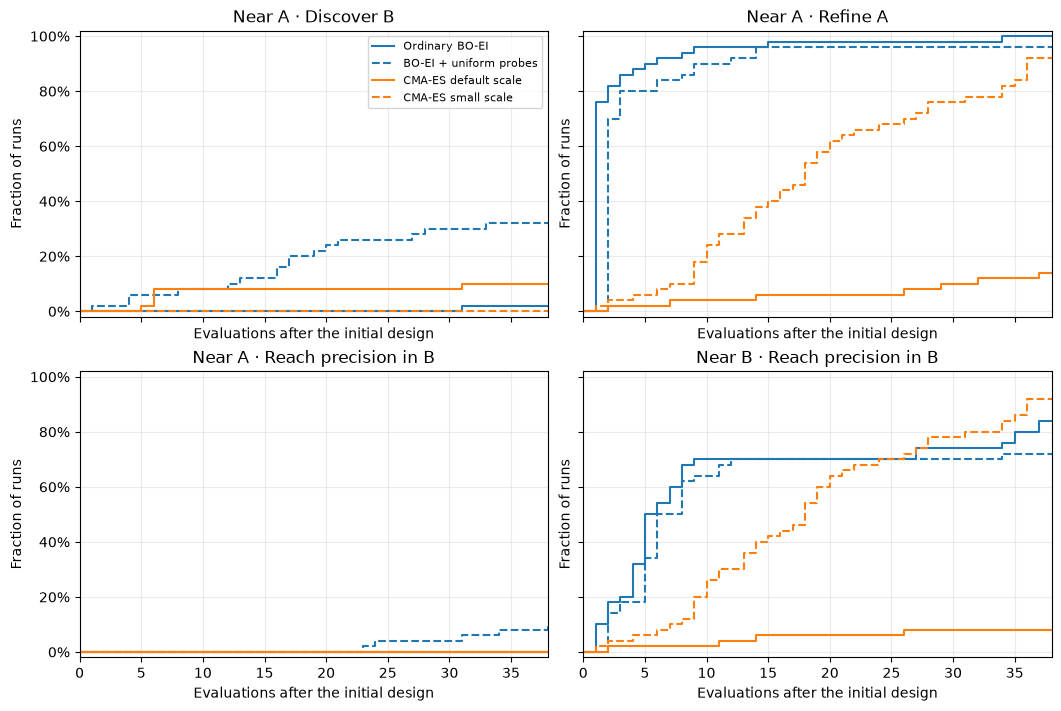

In [5]:
styles = {
    "Ordinary BO-EI": ("tab:blue", "-"),
    "BO-EI + uniform probes": ("tab:blue", "--"),
    "CMA-ES default scale": ("tab:orange", "-"),
    "CMA-ES small scale": ("tab:orange", "--"),
}
panels = [
    ("Near A", "discovery_call", "Near A · Discover B"),
    ("Near A", "refine_a_call", "Near A · Refine A"),
    ("Near A", "precision_call", "Near A · Reach precision in B"),
    ("Near B", "precision_call", "Near B · Reach precision in B"),
]

fig, axes = plt.subplots(
    2, 2, figsize=(10.5, 7), sharex=True, sharey=True, layout="constrained"
)
calls = np.arange(remaining + 1)

for ax, (state, column, title) in zip(axes.flat, panels):
    for arm, (colour, linestyle) in styles.items():
        group = trials.loc[(trials["state"] == state) & (trials["arm"] == arm)]
        hit_calls = group[column].fillna(budget + 1).to_numpy() - initial_calls
        rate = (hit_calls[:, None] <= calls).mean(axis=0)
        ax.step(calls, rate, where="post", color=colour, linestyle=linestyle, label=arm)

    ax.set(
        title=title,
        xlabel="Evaluations after the initial design",
        ylabel="Fraction of runs",
        xlim=(0, remaining),
        ylim=(-0.02, 1.02),
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=8)
fig.savefig(run_dir / "target_hit_curves.png", dpi=180)
plt.show()

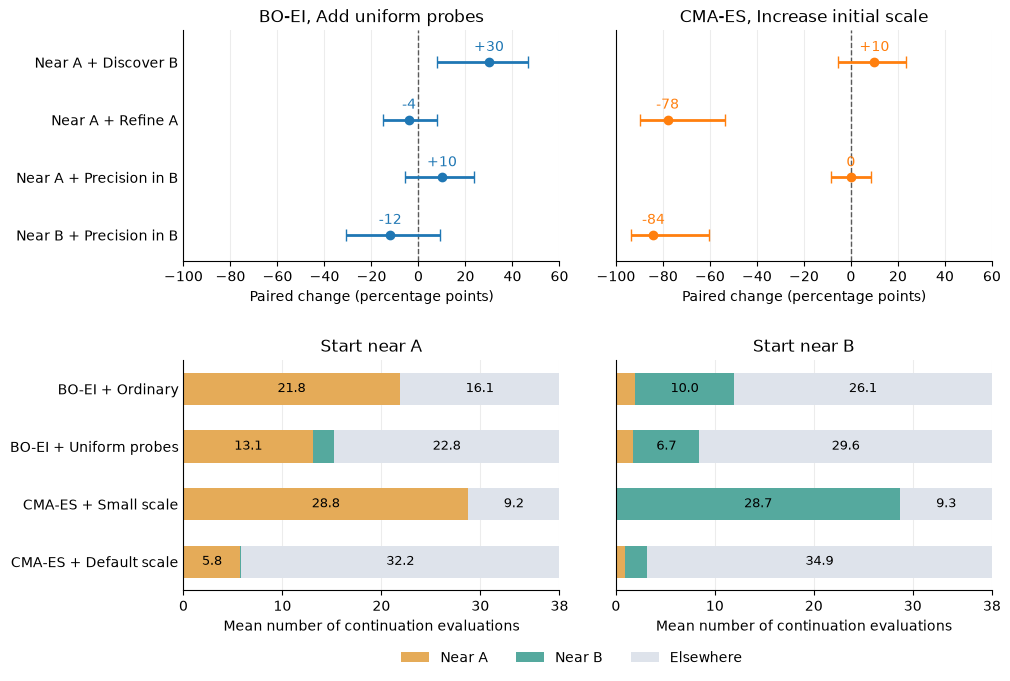

In [9]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

effects = pd.read_csv(run_dir / "paired_effects.csv")
runs = [
    json.loads(line)
    for line in (run_dir / "runs.jsonl").read_text(encoding="utf-8").splitlines()
]

targets = [
    ("Near A", "Discover B"),
    ("Near A", "Refine A"),
    ("Near A", "Reach precision"),
    ("Near B", "Reach precision"),
]
target_labels = [
    "Near A + Discover B",
    "Near A + Refine A",
    "Near A + Precision in B",
    "Near B + Precision in B",
]
contrasts = [
    ("Ordinary BO-EI", "BO-EI + uniform probes",
     "BO-EI, Add uniform probes", "tab:blue"),
    ("CMA-ES small scale", "CMA-ES default scale",
     "CMA-ES, Increase initial scale", "tab:orange"),
]
arm_labels = {
    "Ordinary BO-EI": "BO-EI + Ordinary",
    "BO-EI + uniform probes": "BO-EI + Uniform probes",
    "CMA-ES small scale": "CMA-ES + Small scale",
    "CMA-ES default scale": "CMA-ES + Default scale",
}

# Count the new evaluations within each neighbourhood.
locations = []
for run in runs:
    X = np.asarray(run["X"])[initial_calls:]
    near_a = np.sum(np.linalg.norm(X - BASIN_A, axis=1) < 0.5)
    near_b = np.sum(np.linalg.norm(X - BASIN_B, axis=1) < 0.5)
    locations.append({
        "state": run["state"],
        "arm": run["arm"],
        "Near A": near_a,
        "Near B": near_b,
        "Elsewhere": len(X) - near_a - near_b,
    })

mean_calls = pd.DataFrame(locations).groupby(["state", "arm"]).mean()

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7))
fig.subplots_adjust(
    left=0.21, right=0.98, bottom=0.14, top=0.94,
    wspace=0.15, hspace=0.43,
)

# Panel A. Paired effects and confidence intervals.
y = np.arange(len(targets))
for col, (control, treatment, title, colour) in enumerate(contrasts):
    ax = axes[0, col]
    rows = effects.loc[
        (effects["control"] == control) & (effects["treatment"] == treatment)
    ].set_index(["state", "target"]).loc[targets]

    change = rows["change_pp"].to_numpy()
    errors = [
        change - rows["low_pp"].to_numpy(),
        rows["high_pp"].to_numpy() - change,
    ]

    ax.axvline(0, color="0.35", linestyle="--", linewidth=1)
    ax.errorbar(change, y, xerr=errors, fmt="o", color=colour,
                capsize=4, linewidth=2)

    for value, row in zip(change, y):
        ax.annotate(
            f"{value:+.0f}" if value else "0", (value, row),
            xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=10, color=colour,
        )

    ax.set(
        title=title, xlim=(-100, 60), xticks=np.arange(-100, 61, 20),
        ylim=(3.45, -0.55), yticks=y,
        yticklabels=target_labels if col == 0 else [""] * len(y),
        xlabel="Paired change (percentage points)",
    )

# Panel B. Average allocation of the 38 continuation evaluations.
colours = {"Near A": "#E5AB58", "Near B": "#55A99E", "Elsewhere": "#DEE3EB"}

for col, state in enumerate(("Near A", "Near B")):
    ax = axes[1, col]
    rows = mean_calls.loc[state].loc[list(arm_labels)]
    left = np.zeros(len(rows))

    for area, colour in colours.items():
        values = rows[area].to_numpy()
        ax.barh(y, values, left=left, color=colour, height=0.56, label=area)
        for row, start, value in zip(y, left, values):
            if value >= 4.5:
                ax.text(start + value / 2, row, f"{value:.1f}",
                        ha="center", va="center", fontsize=9)
        left += values

    ax.set(
        title=f"Start near {state[-1]}", xlim=(0, remaining),
        ylim=(3.5, -0.5), yticks=y,
        yticklabels=list(arm_labels.values()) if col == 0 else [""] * len(y),
        xlabel="Mean number of continuation evaluations",
    )
    ax.set_xticks([0, 10, 20, 30, remaining])

for ax in axes.flat:
    ax.grid(axis="x", alpha=0.23)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right"]].set_visible(False)

handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.58, 0.015),
           ncol=3, frameon=False)

fig.savefig(run_dir / "exploration_exploitation.png", dpi=220, bbox_inches="tight")
plt.show()